# EDA: distribución de clases y ejemplos

Requiere la caché de entrenamiento (`python -m src.data --config configs/local.yaml --build-cache`).

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))
import src  # activa el shim de distutils para TF 2.18
import matplotlib.pyplot as plt
import numpy as np
from src.classes import CLASSES
from src.config import load_config
from src.data import ClassCache, cache_path

cfg = load_config("../configs/local.yaml")
cache = ClassCache(cache_path(cfg["paths"]["processed"], cfg["data"]["img_size"]))
counts = np.array([len(i) for i in cache.index])
print(f"{len(cache.labels)} imágenes, {len(counts)} clases | media {counts.mean():.1f}, mín {counts.min()} ({CLASSES[counts.argmin()]}), máx {counts.max()} ({CLASSES[counts.argmax()]})")

12753 imágenes, 104 clases | media 122.6, mín 18 (moon orchid), máx 782 (iris)


## Desbalance de clases

Este desbalance es la razón para usar F1 macro. El conjunto destilado, en cambio, queda balanceado por construcción (IPC por clase).

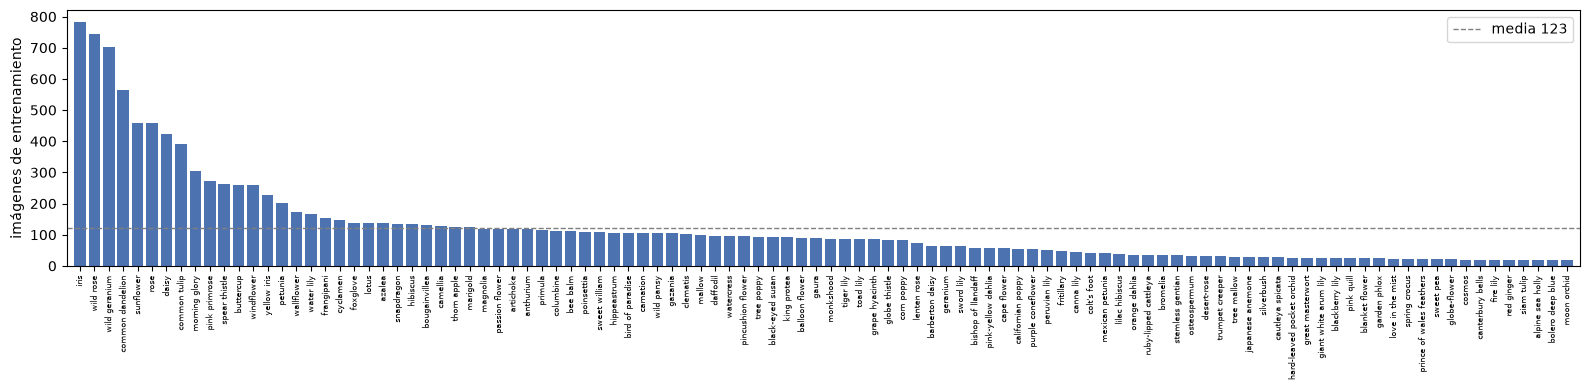

In [2]:
order = np.argsort(counts)[::-1]
fig, ax = plt.subplots(figsize=(16, 4))
ax.bar(range(len(counts)), counts[order], color="#4C72B0")
ax.axhline(counts.mean(), color="gray", ls="--", lw=1, label=f"media {counts.mean():.0f}")
ax.set_xticks(range(len(counts)), [CLASSES[i] for i in order], rotation=90, fontsize=6)
ax.set_ylabel("imágenes de entrenamiento"); ax.legend(); ax.margins(x=0.005)
fig.tight_layout()

## Clases fáciles de confundir (Tabla 2 del reporte)

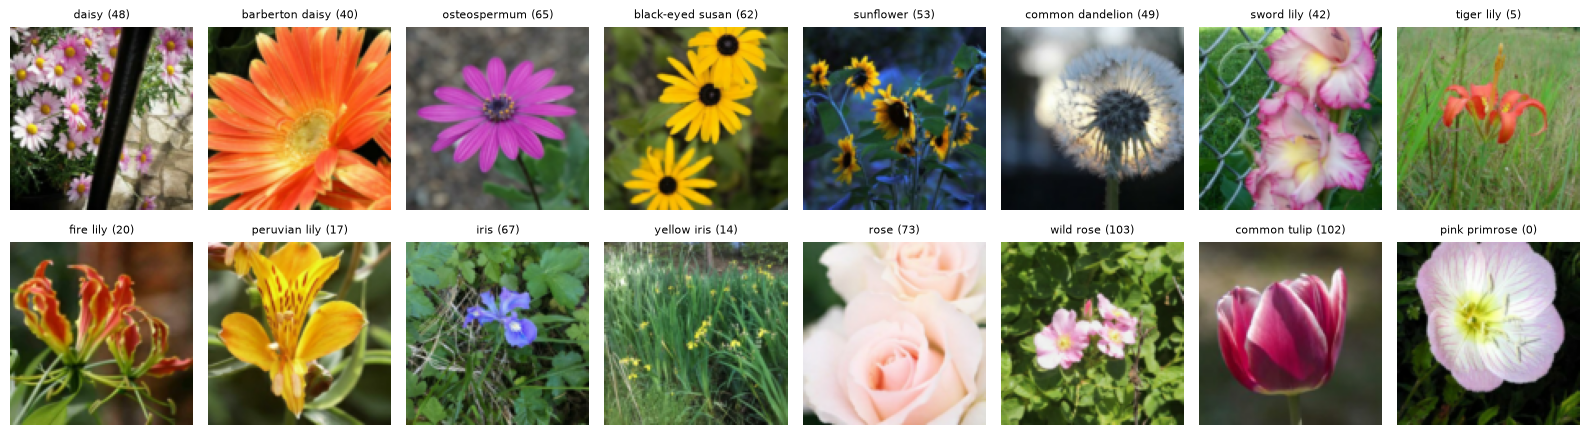

In [3]:
groups = [48, 40, 65, 62, 53, 49, 42, 5, 20, 17, 67, 14, 73, 103, 102, 0]
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for ax, c in zip(axes.ravel(), groups):
    ax.imshow(cache.sample(c, 1, rng)[0]); ax.set_title(f"{CLASSES[c]} ({c})", fontsize=8); ax.axis("off")
fig.tight_layout()